<img src="../Images/RWTH_Logo.png" alt="Engineering Toolkit" width="200px" >

*Areeb Ahmed | Mechanical Engineer*

# Pipe Sizing

- Using Darcy Weisbach Formula
- ASME B31.3 (Process Piping) and B31.1 (Power piping)
- Major and Minor losses
- Velocity recommended for liquids 0- 5m/s
- Velocity recomeded for saturated steam 15-30 m/s
- Superheated steam 30-50 m/s
- Gases with high condensing points 50-80 m/s

In [3]:
import sys
sys.path.append('..')  # Goes up one level to the workspace root

from utils.Appendix.unit_convertors import *
from utils.Appendix.thermofluids.pipe_flow import *
from utils.Appendix.materials import get_material
from CoolProp.CoolProp import PropsSI

crane_data = load_crane_data('./../utils/Catalogs/equivalent_lengths.csv')

fluid_name = "Water"  # directly from CoolProp
T = Temperature.c_to_k(180)            # K
P = Pressure.bar_to_pa(5)               # Pa
pipe_length = 50.0    # m
mass_flowrate = 3600  #kg/hr
density = PropsSI('D','T',T,'P',P,fluid_name)
Q = np.round(mass_flowrate/density/3600,3)             # m³/s (desired volumetric flow)
material = get_material("ASTM A106B")
Length = 50 #m
n_elbow = 3
n_valve = 3
n_tee_straight = 5
n_tee_branch = 4

v_max= 30 #m/s

sizer = PipeSizer(
    fluid_name=fluid_name,
    material=material,
    T=T,
    P=P,
    length=pipe_length
)

D_suggested = sizer.size_for_max_velocity(Q, v_max)
print(f"Suggested pipe diameter based on max velocity: {D_suggested:.3f} m")

# -------------------------------
# 4. Create Pipe and PipeFlow objects
# -------------------------------
pipe = Pipe(diameter=D_suggested, length=pipe_length, material=material)
flow = PipeFlow(pipe, fluid_name=fluid_name, T=T, P=P)  # CoolProp fluid

# -------------------------------
# 5. Build the pipeline (major + minor losses)
# -------------------------------
line = PipeLine()

# Major loss (pipe friction)
line.add(PipeElement(flow))

# Minor losses (fittings with automatic K from Crane CSV)
line.add(CraneMinorLoss("elbow_90_standard", flow, crane_data, count=4))
line.add(CraneMinorLoss("tee_straight", flow, crane_data, count=2))
line.add(CraneMinorLoss("tee_branch", flow, crane_data, count=1))

# -------------------------------
# 6. Compute total pressure drop
# -------------------------------
dp_total = line.total_pressure_drop(Q)
print(f"Total pressure drop including fittings: {dp_total/1000:.2f} kPa")

# -------------------------------
# 7. Optional: check Reynolds number
# -------------------------------
Re = flow.reynolds(Q)
print(f"Reynolds number at Q={Q} m³/s: {Re:.0f}")


Suggested pipe diameter based on max velocity: 0.131 m
Total pressure drop including fittings: 10.94 kPa
Reynolds number at Q=0.405 m³/s: 638785


You may calculate the pressure drop for different pipe sizes and the corresponding velocities and see if they fall within the recommended ranges. It also outputs the projected cost of the pipeline in terms of raw materials. There is a function built for this.

All costs are based on kenyan suppliers but using USD assuming each pipe is 5.8m.

Make sure to integrate pipe, valve and fitting costs (currently only pipe cost enabled)

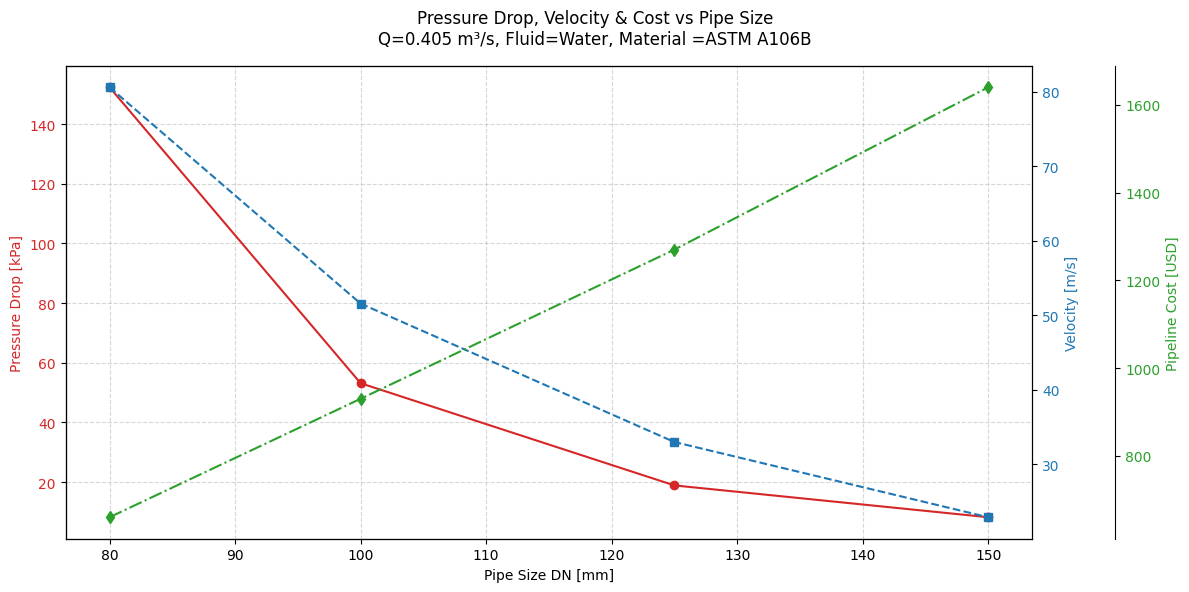

In [4]:
# Load catalog from CSV
pipe_catalog = load_pipe_catalog("./../utils/Catalogs/pipe catalog.csv")

fittings = [("elbow_90_standard", n_elbow), ("tee_straight", n_tee_straight), ("gate_valve_open", n_valve),("tee_branch", n_tee_branch)]

# Pass loaded catalog directly
sizer.plot_performance_vs_size(min_D=0.08, max_D=0.15, Q=Q, fittings=fittings, catalog=pipe_catalog)


## Insulation of Pipes
Assumption
- Ambient remains constant
- Temperature of pipe inner wall is the temperature of the fluid